# 4. Linear Filtering

Practice for module 4: convolution from scratch and its properties, separable Gaussian filtering and its
cost, Gaussian vs median vs bilateral denoising, and template matching with SSD vs normalized
cross-correlation under a brightness change.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

def make_image(n=128):
    y, x = np.mgrid[:n, :n] / n
    img = 0.3 + 0.3 * x
    img[(x - 0.3) ** 2 + (y - 0.35) ** 2 < 0.04] = 0.9
    img[(x > 0.55) & (x < 0.9) & (y > 0.55) & (y < 0.85)] = 0.1
    img[(y > 0.1) & (y < 0.3) & (x > 0.6)] = 0.5 + 0.3 * np.sign(np.sin(2 * np.pi * 12 * x[(y > 0.1) & (y < 0.3) & (x > 0.6)]))
    return img

def psnr(a, b):
    return 10 * np.log10(1 / np.mean((a - b) ** 2))

img = make_image()

## 4.1 Convolution and its properties

`g[n] = Σ f[k] h[n − k]`. Checked numerically: commutative, associative, distributive, the impulse is the
identity and a shifted impulse shifts the signal. Correlation is the same sum without the flip.

In [2]:
def conv1d(f, h):
    out = np.zeros(len(f) + len(h) - 1)
    for k, fk in enumerate(f):
        out[k:k + len(h)] += fk * h
    return out

f, h1, h2 = rng.normal(size=20), rng.normal(size=5), rng.normal(size=4)
delta = np.zeros(5); delta[0] = 1
shift = np.zeros(5); shift[3] = 1
print("matches np.convolve:", np.allclose(conv1d(f, h1), np.convolve(f, h1)))
print("commutative:", np.allclose(conv1d(f, h1), conv1d(h1, f)))
print("associative:", np.allclose(conv1d(conv1d(f, h1), h2), conv1d(f, conv1d(h1, h2))), "(cascade = convolve the kernels)")
print("distributive:", np.allclose(conv1d(f, h1 + h1[::-1]), conv1d(f, h1) + conv1d(f, h1[::-1])))
print("impulse is identity:", np.allclose(conv1d(f, delta)[:20], f), "| shifted impulse shifts by 3:", np.allclose(conv1d(f, shift)[3:23], f))
print("correlation = convolution with a flipped kernel:", np.allclose(np.correlate(f, h1, "full"), np.convolve(f, h1[::-1])))

matches np.convolve: True
commutative: True
associative: True (cascade = convolve the kernels)
distributive: True
impulse is identity: True | shifted impulse shifts by 3: True
correlation = convolution with a flipped kernel: True


## 4.2 Separable Gaussian

A 2D Gaussian is the outer product of two 1D Gaussians, so one K×K pass equals a horizontal K-tap pass
followed by a vertical one: `2K` instead of `K²` multiplications per pixel. Kernel width ≈ `2πσ`.

In [3]:
def gauss1d(sigma):
    r = int(np.ceil(np.pi * sigma)); x = np.arange(-r, r + 1)
    g = np.exp(-x ** 2 / (2 * sigma ** 2)); return g / g.sum()

def filter2d(u, k):
    r = k.shape[0] // 2
    return (sliding_window_view(np.pad(u, r, mode="reflect"), k.shape) * k).sum((-2, -1))

def separable(u, g):
    r = len(g) // 2
    u = (sliding_window_view(np.pad(u, ((0, 0), (r, r)), mode="reflect"), len(g), axis=1) * g).sum(-1)
    return (sliding_window_view(np.pad(u, ((r, r), (0, 0)), mode="reflect"), len(g), axis=0) * g).sum(-1)

for sigma in [1, 3, 6]:
    g = gauss1d(sigma); K = len(g)
    t0 = time.perf_counter(); a = filter2d(img, np.outer(g, g)); t1 = time.perf_counter(); b = separable(img, g); t2 = time.perf_counter()
    print(f"σ = {sigma}: kernel {K}x{K}, max diff {np.abs(a - b).max():.1e}, ops/pixel {K * K} vs {2 * K}, "
          f"time {1e3 * (t1 - t0):.1f} ms vs {1e3 * (t2 - t1):.1f} ms")

σ = 1: kernel 9x9, max diff 2.2e-16, ops/pixel 81 vs 18, time 2.9 ms vs 0.6 ms
σ = 3: kernel 21x21, max diff 5.6e-16, ops/pixel 441 vs 42, time 19.9 ms vs 1.1 ms
σ = 6: kernel 39x39, max diff 6.7e-16, ops/pixel 1521 vs 78, time 60.5 ms vs 1.8 ms


## 4.3 Gaussian, median and bilateral filters

* Gaussian: removes Gaussian noise but blurs edges.
* Median: the right tool for salt and pepper, keeps edges, but it is non-linear (not a convolution) and gets
  expensive for big windows.
* Bilateral: weights neighbours by spatial distance *and* brightness difference, so it does not average
  across edges. With `σ_b → ∞` it becomes a plain Gaussian.

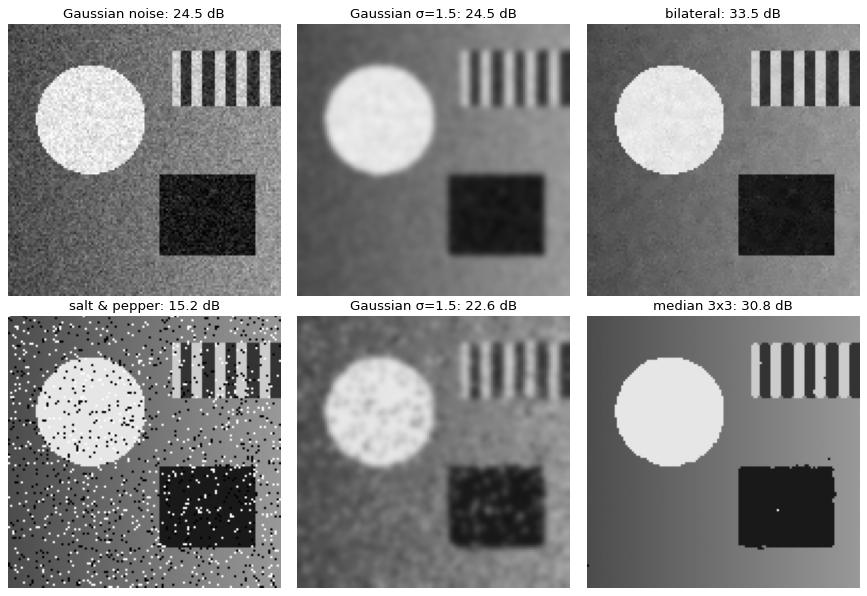

bilateral with σ_b = 1000 vs Gaussian σ = 2: max diff 4.5e-08


In [4]:
def bilateral(u, sigma_s=2.0, sigma_b=0.1):
    r = int(np.ceil(2 * sigma_s)); P = np.pad(u, r, mode="reflect")
    num = np.zeros_like(u); den = np.zeros_like(u)
    for dy in range(-r, r + 1):
        for dx in range(-r, r + 1):
            sh = P[r + dy:r + dy + u.shape[0], r + dx:r + dx + u.shape[1]]
            w = np.exp(-(dy * dy + dx * dx) / (2 * sigma_s ** 2) - (sh - u) ** 2 / (2 * sigma_b ** 2))
            num += w * sh; den += w
    return num / den

median = lambda u, k=3: np.median(sliding_window_view(np.pad(u, k // 2, mode="edge"), (k, k)), axis=(-2, -1))

gn = img + rng.normal(0, 0.06, img.shape)
sp = img.copy(); r = rng.random(img.shape); sp[r < 0.05] = 0; sp[r > 0.95] = 1
results = [("Gaussian noise", gn), ("Gaussian σ=1.5", separable(gn, gauss1d(1.5))), ("bilateral", bilateral(gn)),
           ("salt & pepper", sp), ("Gaussian σ=1.5", separable(sp, gauss1d(1.5))), ("median 3x3", median(sp))]
fig, axes = plt.subplots(2, 3, figsize=(11, 7.5))
for a, (t, u) in zip(axes.ravel(), results):
    a.imshow(u, cmap="gray", vmin=0, vmax=1); a.set_title(f"{t}: {psnr(u, img):.1f} dB"); a.axis("off")
plt.tight_layout(); plt.show()
print(f"bilateral with σ_b = 1000 vs Gaussian σ = 2: max diff {np.abs(bilateral(gn, 2, 1000) - filter2d(gn, np.outer(*[np.exp(-np.arange(-4, 5) ** 2 / 8)] * 2) / np.exp(-np.arange(-4, 5) ** 2 / 8).sum() ** 2)).max():.1e}")

## 4.4 Template matching

Cut a template from the image, then look for it in a version where the target region is darker. Sum of
squared differences is fooled by the brightness change; normalized cross-correlation (zero-mean, unit-norm
patches) is not.

true position (row, col): (8, 25)
SSD best match: (32, 21) | NCC best match: (8, 25)


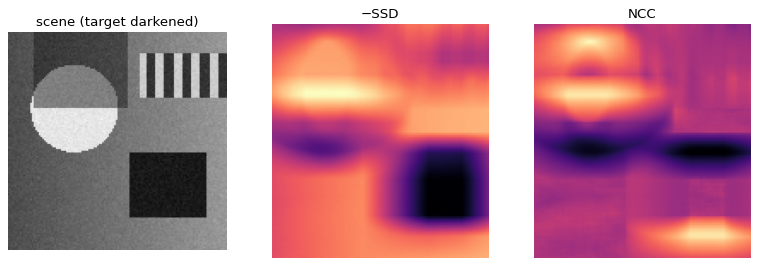

In [5]:
tpl = img[8:30, 25:55].copy()
scene = img.copy(); scene[0:45, 15:70] = 0.5 * scene[0:45, 15:70] + 0.05     # target got darker
scene += rng.normal(0, 0.02, scene.shape)
W = sliding_window_view(scene, tpl.shape)
ssd = ((W - tpl) ** 2).sum((-2, -1))
Wz = W - W.mean((-2, -1), keepdims=True); tz = tpl - tpl.mean()
ncc = (Wz * tz).sum((-2, -1)) / (np.sqrt((Wz ** 2).sum((-2, -1)) * (tz ** 2).sum()) + 1e-12)
print("true position (row, col): (8, 25)")
print("SSD best match:", tuple(map(int, np.unravel_index(ssd.argmin(), ssd.shape))), "| NCC best match:", tuple(map(int, np.unravel_index(ncc.argmax(), ncc.shape))))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].imshow(scene, cmap="gray", vmin=0, vmax=1); axes[0].set_title("scene (target darkened)")
axes[1].imshow(-ssd, cmap="magma"); axes[1].set_title("−SSD")
axes[2].imshow(ncc, cmap="magma"); axes[2].set_title("NCC")
for a in axes: a.axis("off")
plt.show()